# 3. Interest Points, Blobs and SIFT-style Descriptors

Practice for the SIFT module: why edges are poor interest points, scale-normalized Laplacian of Gaussian
and its characteristic scale, Difference of Gaussians as a cheaper approximation, multi-scale blob detection,
and a small SIFT-like descriptor (dominant orientation + 4×4 orientation histograms) matched between an image
and a rotated, rescaled copy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

def gauss_blur(u, s):
    r = int(np.ceil(3 * s)); x = np.arange(-r, r + 1); k = np.exp(-x ** 2 / (2 * s * s)); k /= k.sum()
    u = np.apply_along_axis(lambda row: np.convolve(np.pad(row, r, mode="reflect"), k, "valid"), 1, u)
    return np.apply_along_axis(lambda col: np.convolve(np.pad(col, r, mode="reflect"), k, "valid"), 0, u)

def laplacian(u):
    return np.roll(u, 1, 0) + np.roll(u, -1, 0) + np.roll(u, 1, 1) + np.roll(u, -1, 1) - 4 * u

## 3.1 Characteristic scale

The scale-normalized LoG response `σ² ∇²(G_σ * f)` at the centre of a disk of radius r peaks at
`σ = r / √2`. The peak σ is the blob's characteristic scale; for two matching blobs the ratio of their peak
σ's is their relative scale. DoG `G_{kσ} − G_σ ≈ (k − 1) σ² ∇²G` gives the same peak more cheaply.

r =  6: LoG peak σ =  4.00, DoG peak σ =  4.00, r/√2 =  4.24


r = 10: LoG peak σ =  6.80, DoG peak σ =  6.40, r/√2 =  7.07


r = 16: LoG peak σ = 11.20, DoG peak σ = 10.00, r/√2 = 11.31


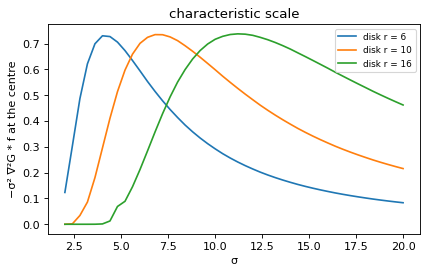

In [2]:
yy, xx = np.mgrid[:260, :260]
sigmas = np.linspace(2, 20, 46)
plt.figure(figsize=(6, 3.4))
for r in [6, 10, 16]:
    disk = ((xx - 80) ** 2 + (yy - 80) ** 2 < r * r).astype(float)
    log_r = [-(s * s) * laplacian(gauss_blur(disk, s))[80, 80] for s in sigmas]
    dog_r = [(gauss_blur(disk, s) - gauss_blur(disk, 1.2 * s))[80, 80] / 0.2 for s in sigmas]
    s_log, s_dog = sigmas[np.argmax(log_r)], sigmas[np.argmax(dog_r)]
    print(f"r = {r:2d}: LoG peak σ = {s_log:5.2f}, DoG peak σ = {s_dog:5.2f}, r/√2 = {r / np.sqrt(2):5.2f}")
    plt.plot(sigmas, log_r, label=f"disk r = {r}")
plt.xlabel("σ"); plt.ylabel("−σ² ∇²G * f at the centre"); plt.legend(fontsize=8); plt.title("characteristic scale"); plt.show()

## 3.2 Edges vs corners vs blobs

Sum of squared differences between a patch and the same patch shifted in every direction. On an edge the
SSD stays near zero along the edge (the position is ambiguous); at a corner or a blob it rises in every
direction, so the point is well localized.

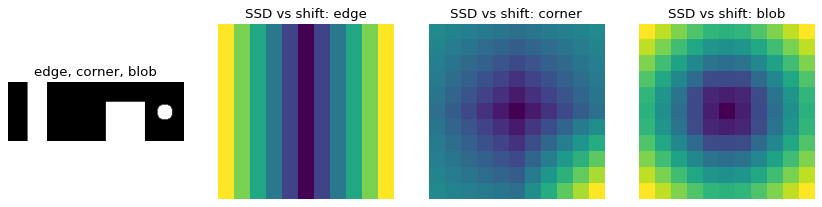

In [3]:
img = np.zeros((60, 180))
img[:, 20:40] = 1                                                         # an edge at x = 40 (x 40..59 is flat)
img[20:60, 100:140] = 1                                                   # a corner at (100, 20)
img[(xx[:60, :180] - 160) ** 2 + (yy[:60, :180] - 30) ** 2 < 64] = 1     # a blob
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
axes[0].imshow(img, cmap="gray"); axes[0].axis("off"); axes[0].set_title("edge, corner, blob")
for ax, (cx, cy, t) in zip(axes[1:], [(40, 30, "edge"), (100, 20, "corner"), (160, 30, "blob")]):
    P = img[cy - 6:cy + 7, cx - 6:cx + 7]
    E = np.array([[((img[cy - 6 + dy:cy + 7 + dy, cx - 6 + dx:cx + 7 + dx] - P) ** 2).sum() for dx in range(-5, 6)] for dy in range(-5, 6)])
    ax.imshow(E, cmap="viridis"); ax.set_title(f"SSD vs shift: {t}"); ax.axis("off")
plt.show()

## 3.3 Multi-scale blob detection

Search for extrema of the normalized LoG over `(x, y, σ)`, not just `(x, y)`. Each detection comes with its
own scale, drawn as a circle of radius `√2 σ`.

6 blobs found (true: 6)
  at ( 40,  40), σ =  4.00 -> radius ≈   5.7
  at ( 60, 115), σ = 10.37 -> radius ≈  14.7
  at (110,  50), σ =  8.72 -> radius ≈  12.3
  at (150, 120), σ =  3.36 -> radius ≈   4.8
  at (180,  40), σ =  6.17 -> radius ≈   8.7
  at (190, 125), σ =  5.66 -> radius ≈   8.0


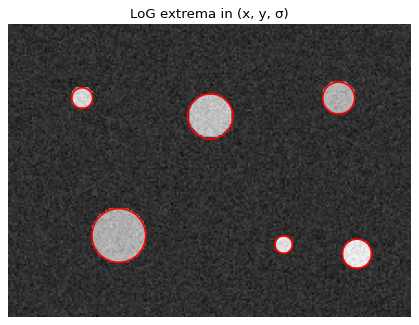

In [4]:
scene = np.zeros((160, 220)) + 0.1
blobs_true = [(40, 40, 6), (110, 50, 12), (180, 40, 9), (60, 115, 15), (150, 120, 5), (190, 125, 8)]
for cx, cy, r in blobs_true:
    scene[(xx[:160, :220] - cx) ** 2 + (yy[:160, :220] - cy) ** 2 < r * r] = rng.uniform(0.7, 1.0)
scene += rng.normal(0, 0.05, scene.shape)

def log_stack(u, sigmas):
    return np.stack([-(s * s) * laplacian(gauss_blur(u, s)) for s in sigmas])

def detect(u, sigmas, thr):
    S = log_stack(u, sigmas)
    from numpy.lib.stride_tricks import sliding_window_view
    mx = sliding_window_view(np.pad(S, 1, constant_values=-np.inf), (3, 3, 3)).max((-3, -2, -1))
    k, y, x = np.nonzero((S == mx) & (S > thr))
    H, W = u.shape; m = 2 * sigmas[k]                     # drop responses that touch the image border
    ok = (x >= m) & (y >= m) & (x < W - m) & (y < H - m)
    return [(int(x_), int(y_), float(sigmas[k_])) for k_, y_, x_ in zip(k[ok], y[ok], x[ok])]

sig = 2 ** np.linspace(1, 4, 25)
dets = detect(scene, sig, 0.25)
print(f"{len(dets)} blobs found (true: {len(blobs_true)})")
for x, y, s in sorted(dets):
    print(f"  at ({x:3d}, {y:3d}), σ = {s:5.2f} -> radius ≈ {np.sqrt(2) * s:5.1f}")
plt.figure(figsize=(6.5, 4.8)); plt.imshow(scene, cmap="gray")
for x, y, s in dets:
    plt.gca().add_patch(plt.Circle((x, y), np.sqrt(2) * s, fill=False, color="r", lw=1.5))
plt.axis("off"); plt.title("LoG extrema in (x, y, σ)"); plt.show()

## 3.4 A SIFT-like descriptor and matching

Around each keypoint take a window proportional to its scale, find the dominant gradient orientation
(peak of a 36-bin histogram) and rotate the window so that orientation points the same way. The descriptor
is 4×4 cells × 8 orientation bins = 128 numbers, normalized. Matching uses L2 distance (smaller is better)
with Lowe's ratio test. The test image is a textured scene and a copy rotated by 35° and scaled by 1.3.

keypoints: 126 and 154; matches after ratio test: 90, geometrically correct: 90
median ratio of matched characteristic scales: 1.30 (true scale 1.3; σ levels are 2^(1/8) ≈ 1.09 apart)


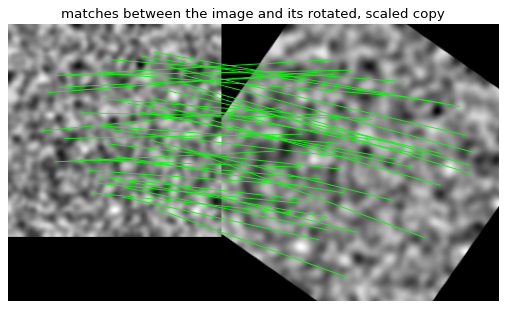

In [5]:
def warp(u, A, t, shape):
    """output(p) = u(A^-1 (p - t)), bilinear."""
    H, W = shape; yy, xx = np.mgrid[:H, :W]
    q = np.linalg.inv(A) @ (np.stack([xx.ravel(), yy.ravel()]) - t[:, None])
    x, y = q; x0, y0 = np.floor(x).astype(int), np.floor(y).astype(int); dx, dy = x - x0, y - y0
    def at(yi, xi):
        ok = (yi >= 0) & (yi < u.shape[0]) & (xi >= 0) & (xi < u.shape[1])
        return np.where(ok, u[yi.clip(0, u.shape[0] - 1), xi.clip(0, u.shape[1] - 1)], 0)
    return (at(y0, x0) * (1 - dx) * (1 - dy) + at(y0, x0 + 1) * dx * (1 - dy) + at(y0 + 1, x0) * (1 - dx) * dy + at(y0 + 1, x0 + 1) * dx * dy).reshape(H, W)

tex = gauss_blur(rng.random((200, 200)), 3.0); tex = (tex - tex.min()) / np.ptp(tex)
ang, sc = np.deg2rad(35), 1.3
A = sc * np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]])
t = np.array([130.0, 130.0]) - A @ np.array([100.0, 100.0])
tex2 = warp(tex, A, t, (260, 260))

def descriptor(u, x, y, s):
    R = int(round(6 * s)); gy, gx = np.gradient(gauss_blur(u, 1.0))
    ys, xs = np.mgrid[-R:R + 1, -R:R + 1]; inside = (xs ** 2 + ys ** 2 <= R * R)
    px, py = (x + xs).clip(0, u.shape[1] - 1), (y + ys).clip(0, u.shape[0] - 1)
    mag, ori = np.hypot(gx, gy)[py, px], np.arctan2(gy, gx)[py, px]
    w = mag * inside * np.exp(-(xs ** 2 + ys ** 2) / (2 * (3 * s) ** 2))
    hist = np.bincount((((ori % (2 * np.pi)) / (2 * np.pi) * 36).astype(int) % 36).ravel(), w.ravel(), 36)
    theta = (np.argmax(hist) + 0.5) * 2 * np.pi / 36
    c, s_ = np.cos(-theta), np.sin(-theta)
    rx, ry = c * xs - s_ * ys, s_ * xs + c * ys                       # coordinates in the rotated frame
    cell_x = ((rx + R) / (2 * R + 1) * 4).astype(int).clip(0, 3); cell_y = ((ry + R) / (2 * R + 1) * 4).astype(int).clip(0, 3)
    obin = (((ori - theta) % (2 * np.pi)) / (2 * np.pi) * 8).astype(int) % 8
    d = np.bincount((cell_y * 32 + cell_x * 8 + obin).ravel(), w.ravel(), 128)
    d /= np.linalg.norm(d) + 1e-12; d = np.minimum(d, 0.2); return d / (np.linalg.norm(d) + 1e-12)

k1 = [k for k in detect(tex, sig, 0.02) if 25 < k[0] < 175 and 25 < k[1] < 175]
k2 = [k for k in detect(tex2, sig, 0.02) if 20 < k[0] < 240 and 20 < k[1] < 240]
D1 = np.array([descriptor(tex, *k) for k in k1]); D2 = np.array([descriptor(tex2, *k) for k in k2])
dist = np.linalg.norm(D1[:, None] - D2[None], axis=2)
order = np.argsort(dist, 1)
good, correct = [], 0
for i in range(len(k1)):
    j, j2 = order[i, 0], order[i, 1]
    if dist[i, j] < 0.8 * dist[i, j2]:
        good.append((i, j))
        pred = A @ np.array(k1[i][:2], float) + t
        correct += np.linalg.norm(pred - np.array(k2[j][:2])) < 4
print(f"keypoints: {len(k1)} and {len(k2)}; matches after ratio test: {len(good)}, geometrically correct: {correct}")
s_ratio = np.median([k2[j][2] / k1[i][2] for i, j in good])
print(f"median ratio of matched characteristic scales: {s_ratio:.2f} (true scale 1.3; σ levels are 2^(1/8) ≈ 1.09 apart)")

fig, ax = plt.subplots(figsize=(10, 4.5))
canvas = np.zeros((260, 460)); canvas[:200, :200] = tex; canvas[:, 200:] = tex2
ax.imshow(canvas, cmap="gray")
for i, j in good[:40]:
    ax.plot([k1[i][0], k2[j][0] + 200], [k1[i][1], k2[j][1]], "-", lw=0.8, color="lime")
ax.axis("off"); ax.set_title("matches between the image and its rotated, scaled copy"); plt.show()